**Presentation Code**  
Authors: Eadan (Daisy) Gibb, Elliot Barr

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
R = 1.0
N = 400

Velocity Verlet  
https://www.algorithm-archive.org/contents/verlet_integration/verlet_integration.html

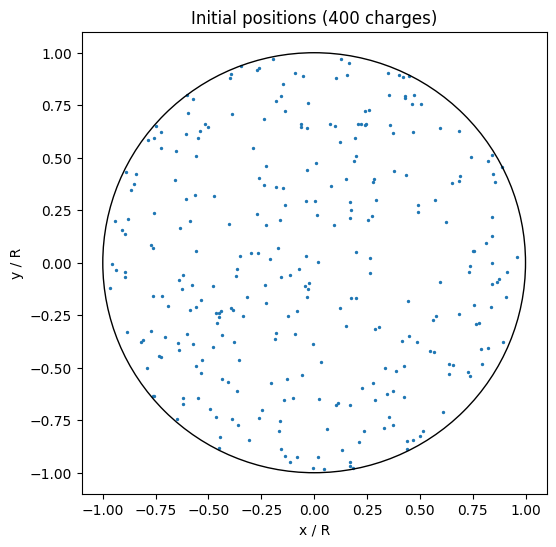

In [ ]:
dt = 1e-3
time = 10
# For this we are using unit values like Q is just unit charge, so k,Q,R,etc = 1

rng = np.random.default_rng(0)
randomRadius = R*np.sqrt(rng.random(N)) #Picks a uniformally distributed radius
randomAngle = 2*np.pi*rng.random(N) #Picks a random angle
position = np.zeros((N,2))
x = randomRadius*np.cos(randomAngle)
y = randomRadius*np.sin(randomAngle)
position[:, 0] = x
position[:, 1] = y
p0 = position.copy()
velocity = np.zeros((N,2)) # We can say all start at rest

# Coulombs Forces on all charges
# kq^2 * (ri-rj)/|ri-rj|^3
def forces(P):
    #Need to calculate how far in x and y one particle is from another
    pSize = len(P)
    dx = np.zeros((pSize,pSize))
    dy = np.zeros((pSize,pSize))
    for i in range(pSize):
        for j in range(pSize):
            dx[i,j] = P[i,0] - P[j,0]
            dy[i,j] = P[i,1] - P[j,1]
    # Need to get total distance from i and j
    distance = np.sqrt(dx**2 + dy**2)
    # Diagonals will be it calculating itself so need to set distance to inf
    np.fill_diagonal(dist, np.inf)
    # Force Components
    Fx = np.sum(dx/ distance**3, axis=1)
    Fy = np.sum(dy/ distance**3, axis=1)
    return np.column_stack([Fx,Fy])

def potentialEnergy(P):
    #Need to calculate how far in x and y one particle is from another
    pSize = len(P)
    dx = np.zeros((pSize,pSize))
    dy = np.zeros((pSize,pSize))
    for i in range(pSize):
        for j in range(pSize):
            dx[i,j] = P[i,0] - P[j,0]
            dy[i,j] = P[i,1] - P[j,1]
    # Need to get total distance from i and j
    distance = np.sqrt(dx**2 + dy**2)
    # Diagonals will be it calculating itself so need to set distance to inf
    np.fill_diagonal(distance, np.inf)
    # Potential Energy
    U = np.sum(1/distance)/2
    return U

# Inital start position chart
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(P0[:, 0], P0[:, 1], s=2)
ax.add_patch(plt.Circle((0, 0), R, fill=False, color='k'))
ax.set_xlabel('x / R')
ax.set_ylabel('y / R')
ax.set_title(f'Initial positions ({N} charges)')
plt.show()
